# 01. Dữ liệu ESC-50 và EDA
Nhánh GitHub: `01-data-eda` (chạy được trên CPU)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip -q install soundfile
from google.colab import drive
drive.mount('/content/drive')
import sys
sys.path.append('/content/drive/MyDrive/ESC50')
from esc_lib import *
setup(gpu=False)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Mixup: BẬT | quick: False | kết quả lưu ở: /content/drive/MyDrive/ESC50/results_mixup


## Nguồn dữ liệu
ESC-50: https://github.com/karolpiczak/ESC-50. Hàm `setup()` ở ô trên tự chạy `git clone --depth 1` về `/content/ESC-50` (khoảng 1 phút, mỗi phiên Colab tải lại một lần). Kiểm tra dữ liệu đã có:

In [ ]:
print("Thư mục:", ESC_DIR)
print("Có meta/esc50.csv:", (ESC_DIR / "meta" / "esc50.csv").exists())
print("Số file wav:", len(list(audio_dir.glob("*.wav"))))

Thư mục: /content/ESC-50
Có meta/esc50.csv: True
Số file wav: 2000


## 1. Cấu hình chung

In [ ]:
display(pd.DataFrame(EXPERIMENTS).T.rename_axis("Thí nghiệm"))
print(CFG)

,model,n_mels,specaug
Thí nghiệm,,,
E1,cnn,64,False
E2,cnn,128,False
E3,cnn,64,True
E4,cnn,128,True
E5,crnn,64,False
E6,crnn,128,False
E7,crnn,64,True
E8,crnn,128,True
E9,panns,64,True


{'SAMPLE_RATE': 22050, 'DURATION': 5, 'N_FFT': 1024, 'HOP_LENGTH': 512, 'BATCH_SIZE': 32, 'LR': 0.001, 'WEIGHT_DECAY': 0.01, 'EPOCHS': 80, 'PATIENCE': 80, 'FREQ_MASK_RATIO': 0.125, 'TIME_MASK_PARAM': 20, 'NUM_MASKS': 2, 'CONV_PER_BLOCK': 2, 'LABEL_SMOOTHING': 0.1, 'MIXUP_ALPHA': 0.4, 'MIXUP_PROB': 0.5, 'BASE_AUG': True, 'SHIFT_MAX': 0.5, 'GAIN_DB': 6.0, 'SNR_LIST': [20, 10, 0], 'NUM_CLASSES': 50, 'SEED': 42}


## 2. Dữ liệu ESC-50
2.000 file WAV, 5 giây, 50 lớp, 5 fold. Mỗi file đưa về mono, 22.050 Hz, đúng 5 giây.

In [ ]:
meta, X, X_DEV, y, folds = load_data()
print("Số file:", len(meta), "| số lớp:", len(CLASS_NAMES))
print("Số file mỗi fold:", meta["fold"].value_counts().sort_index().to_dict())
print("Số file mỗi lớp (min/max):", meta["target"].value_counts().min(), meta["target"].value_counts().max())
display(meta.head())

  0%|          | 0/2000 [00:00<?, ?it/s]

X: (2000, 110250) | y: (2000,) | nằm trên: cpu
Số file: 2000 | số lớp: 50
Số file mỗi fold: {1: 400, 2: 400, 3: 400, 4: 400, 5: 400}
Số file mỗi lớp (min/max): 40 40


,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A


### Kiểm tra chất lượng dữ liệu

In [ ]:
class_counts = meta["target"].value_counts()
fold_counts = meta["fold"].value_counts()
per_class_fold = pd.crosstab(meta["target"], meta["fold"])
checks = {
    "Đủ 2.000 file": len(meta) == 2000,
    "Đủ 50 lớp": meta["target"].nunique() == 50,
    "Mỗi lớp đúng 40 file": bool((class_counts == 40).all()),
    "Mỗi fold đúng 400 file": bool((fold_counts == 400).all()),
    "Mỗi lớp có đúng 8 file trong mỗi fold": bool((per_class_fold == 8).all().all()),
    "Không có nhãn trống": bool(meta[["target", "category", "fold"]].notna().all().all()),
    "Không trùng tên file": bool(meta["filename"].is_unique),
    "Mọi file âm thanh đều tồn tại": all((audio_dir / f).exists() for f in meta["filename"]),
}

infos = [sf.info(str(audio_dir / f)) for f in meta["filename"]]
orig_sr = pd.Series([i.samplerate for i in infos])
orig_ch = pd.Series([i.channels for i in infos])
orig_dur = pd.Series([i.duration for i in infos])
checks["Tất cả file mono"] = bool((orig_ch == 1).all())
checks["Tất cả file 44,1 kHz"] = bool((orig_sr == 44100).all())
checks["Tất cả file dài đúng 5 giây"] = bool(np.allclose(orig_dur, 5.0, atol=0.01))

peak = X.abs().amax(dim=1)
checks["Không có NaN/Inf"] = bool(torch.isfinite(X).all())
checks["Không có file im lặng hoàn toàn"] = not bool((peak < 1e-6).any())

pad_sec = np.zeros(len(X))
for k in range(len(X)):
    nz = torch.nonzero(X[k].abs() > 1e-4)
    last = int(nz[-1]) + 1 if len(nz) else 0
    pad_sec[k] = (X.shape[1] - last) / SR

report = pd.DataFrame({"Kiểm tra": list(checks),
                       "Kết quả": ["Đạt" if v else "KHÔNG ĐẠT" for v in checks.values()]})
display(report)
print("Số file bị clip (biên độ đỉnh >= 0,999):", int((peak >= 0.999).sum()))
print("Số file có khoảng lặng cuối >= 0,5 giây:", int((pad_sec >= 0.5).sum()))
print("Số file có khoảng lặng cuối >= 2 giây:", int((pad_sec >= 2).sum()))
print(f"Khoảng lặng cuối dài nhất: {pad_sec.max():.2f} giây")
print(f"Biên độ đỉnh (nhỏ nhất / trung vị / lớn nhất): "
      f"{peak.min().item():.3f} / {peak.median().item():.3f} / {peak.max().item():.3f}")
if not all(checks.values()):
    print("CẢNH BÁO: có mục kiểm tra không đạt, cần xem lại dữ liệu trước khi huấn luyện.")

,Kiểm tra,Kết quả
0,Đủ 2.000 file,Đạt
1,Đủ 50 lớp,Đạt
2,Mỗi lớp đúng 40 file,Đạt
3,Mỗi fold đúng 400 file,Đạt
4,Mỗi lớp có đúng 8 file trong mỗi fold,Đạt
5,Không có nhãn trống,Đạt
6,Không trùng tên file,Đạt
7,Mọi file âm thanh đều tồn tại,Đạt
8,Tất cả file mono,Đạt
9,"Tất cả file 44,1 kHz",Đạt


Số file bị clip (biên độ đỉnh >= 0,999): 524
Số file có khoảng lặng cuối >= 0,5 giây: 373
Số file có khoảng lặng cuối >= 2 giây: 261
Khoảng lặng cuối dài nhất: 4.64 giây
Biên độ đỉnh (nhỏ nhất / trung vị / lớn nhất): 0.013 / 0.755 / 1.415


## 3. Tiền xử lý: Log-Mel, chuẩn hóa, SpecAugment
Waveform → Log-Mel (1 × n_mels × 216) → chuẩn hóa (mean/std của tập train) → SpecAugment (2 mặt nạ tần số, 2 mặt nạ thời gian).

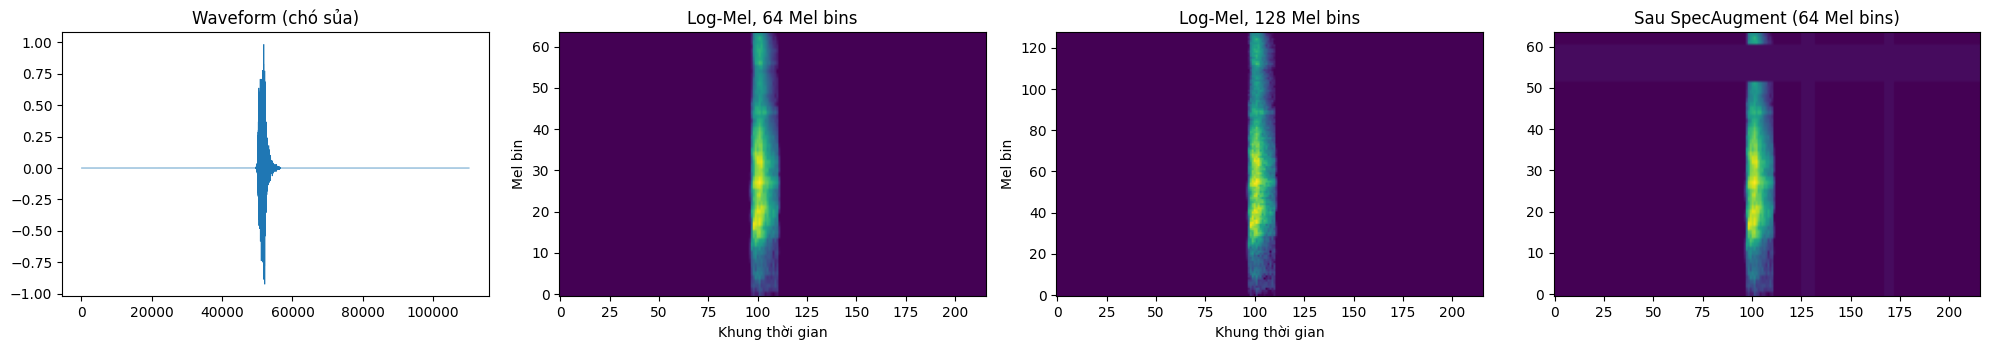

In [ ]:
i = int(np.where(meta["category"] == "dog")[0][0])
wav = X[i:i + 1].to(DEVICE)

fig, axes = plt.subplots(1, 4, figsize=(20, 3.6))
axes[0].plot(X[i].numpy(), linewidth=0.5)
axes[0].set_title("Waveform (chó sủa)")

for ax, n in zip(axes[1:3], (64, 128)):
    spec = LogMel(n).to(DEVICE)(wav)[0, 0].cpu().numpy()
    ax.imshow(spec, origin="lower", aspect="auto")
    ax.set_title(f"Log-Mel, {n} Mel bins")
    ax.set_xlabel("Khung thời gian")
    ax.set_ylabel("Mel bin")

s = LogMel(64).to(DEVICE)(wav)
s = (s - s.mean()) / s.std()
aug = SpecAug(64, CFG["FREQ_MASK_RATIO"], CFG["TIME_MASK_PARAM"], CFG["NUM_MASKS"]).to(DEVICE)(s)
axes[3].imshow(aug[0, 0].cpu().numpy(), origin="lower", aspect="auto")
axes[3].set_title("Sau SpecAugment (64 Mel bins)")
plt.tight_layout()
plt.show()

### Phân tích khám phá dữ liệu (EDA)

fold,1,2,3,4,5,All
Nhóm / Fold,,,,,,
Thiên nhiên và nước,80,80,80,80,80,400
Tiếng ồn đô thị,80,80,80,80,80,400
Âm thanh con người,80,80,80,80,80,400
Âm thanh trong nhà,80,80,80,80,80,400
Động vật,80,80,80,80,80,400
All,400,400,400,400,400,2000


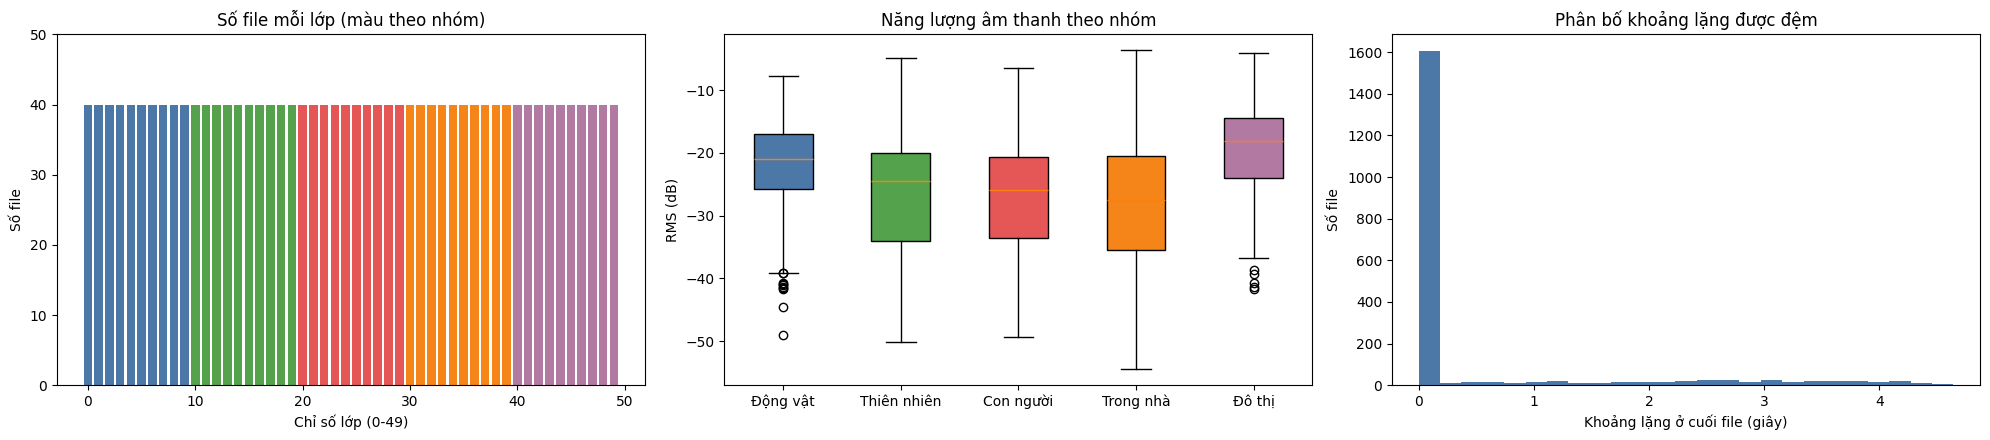

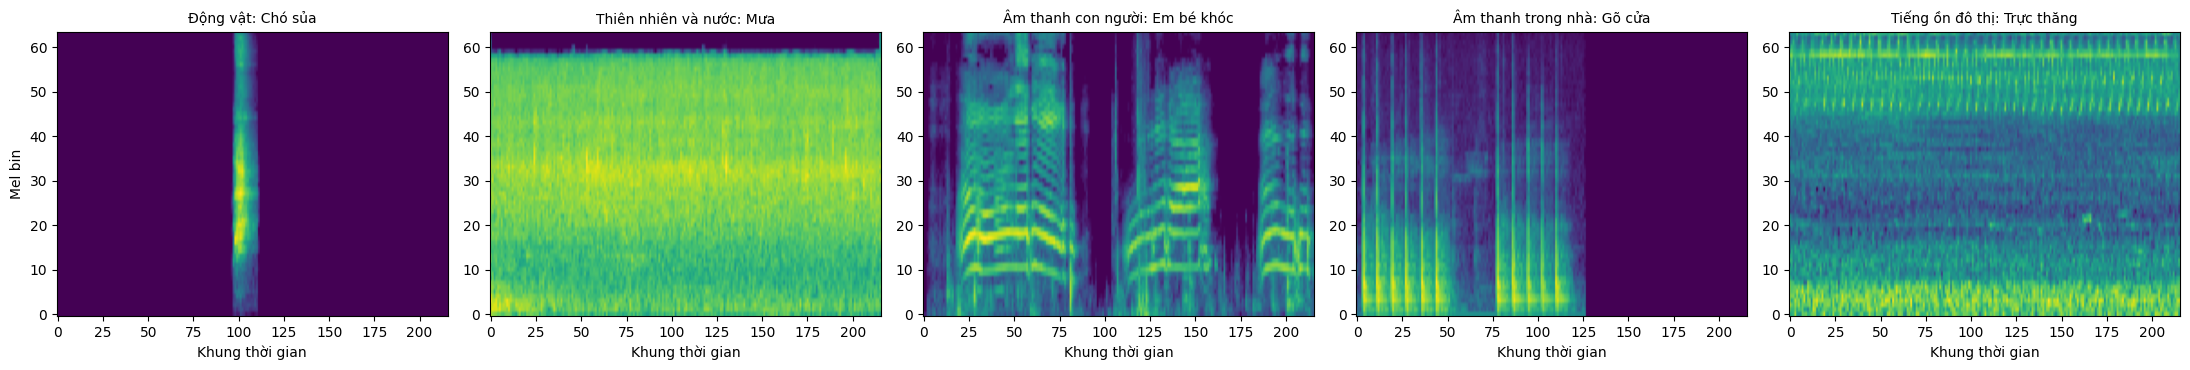

5 lớp có nhiều khoảng lặng được đệm nhất (trung bình, giây):
  Kính vỡ: 2.66
  Hắt hơi: 2.16
  Ho: 1.95
  Gõ cửa: 1.80
  Gà trống gáy: 1.78


In [ ]:
meta["group"] = meta["target"] // 10
meta["group_name"] = meta["group"].map(dict(enumerate(GROUP_NAMES)))
meta["pad_sec"] = pad_sec
GROUP_COLORS = ["#4C78A8", "#54A24B", "#E45756", "#F58518", "#B279A2"]
SHORT_GROUPS = ["Động vật", "Thiên nhiên", "Con người", "Trong nhà", "Đô thị"]

display(pd.crosstab(meta["group_name"], meta["fold"], margins=True).rename_axis("Nhóm / Fold"))

rms_db = 20 * np.log10(X.pow(2).mean(dim=1).sqrt().numpy() + 1e-8)

fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))

counts = meta["target"].value_counts().sort_index()
axes[0].bar(range(50), counts.values, color=[GROUP_COLORS[i // 10] for i in range(50)])
axes[0].set_ylim(0, 50)
axes[0].set_xlabel("Chỉ số lớp (0-49)")
axes[0].set_ylabel("Số file")
axes[0].set_title("Số file mỗi lớp (màu theo nhóm)")

box = axes[1].boxplot([rms_db[meta["group"].values == g] for g in range(5)], patch_artist=True)
for patch, c in zip(box["boxes"], GROUP_COLORS):
    patch.set_facecolor(c)
axes[1].set_xticks(range(1, 6))
axes[1].set_xticklabels(SHORT_GROUPS)
axes[1].set_ylabel("RMS (dB)")
axes[1].set_title("Năng lượng âm thanh theo nhóm")

axes[2].hist(pad_sec, bins=25, color="#4C78A8")
axes[2].set_xlabel("Khoảng lặng ở cuối file (giây)")
axes[2].set_ylabel("Số file")
axes[2].set_title("Phân bố khoảng lặng được đệm")
plt.tight_layout()
plt.show()

fe64 = LogMel(64).to(DEVICE)
fig, axes = plt.subplots(1, 5, figsize=(22, 3.8))
for g, ax in enumerate(axes):
    i = int(np.where(meta["target"].values == g * 10)[0][0])
    spec = fe64(X[i:i + 1].to(DEVICE))[0, 0].cpu().numpy()
    ax.imshow(spec, origin="lower", aspect="auto")
    ax.set_title(f"{GROUP_NAMES[g]}: {VI_LIST[g * 10]}", fontsize=10)
    ax.set_xlabel("Khung thời gian")
axes[0].set_ylabel("Mel bin")
plt.tight_layout()
plt.show()

top_pad = meta.groupby("target")["pad_sec"].mean().sort_values(ascending=False).head(5)
print("5 lớp có nhiều khoảng lặng được đệm nhất (trung bình, giây):")
for t, v in top_pad.items():
    print(f"  {VI_LIST[t]}: {v:.2f}")